# Machine Learning Lab Assignment 10
## Naive Bayes 2: Gaussian Naive Bayes on `Mall_Customers.CSV`

**Objective:**
- Apply **Gaussian Naive Bayes (GaussianNB)** to classify mall customers into spending categories (`High Spender` vs `Standard Spender`).
- Understand Gaussian NB's mathematical assumption that continuous features follow normal distributions $\mathcal{N}(\mu_c, \sigma_c^2)$ within each class.
- Evaluate performance metrics: Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.
- Visualize class-conditional Gaussian distribution curves for `Age` and `Annual Income`.


=== Gaussian Naive Bayes Mall Customers Results ===
Accuracy  : 0.7000 (70.00%)
Precision : 0.6923
Recall    : 0.7200
F1-Score  : 0.7059

Classification Report:
                     precision    recall  f1-score   support

     Standard (<50)       0.71      0.68      0.69        25
High Spender (>=50)       0.69      0.72      0.71        25

           accuracy                           0.70        50
          macro avg       0.70      0.70      0.70        50
       weighted avg       0.70      0.70      0.70        50



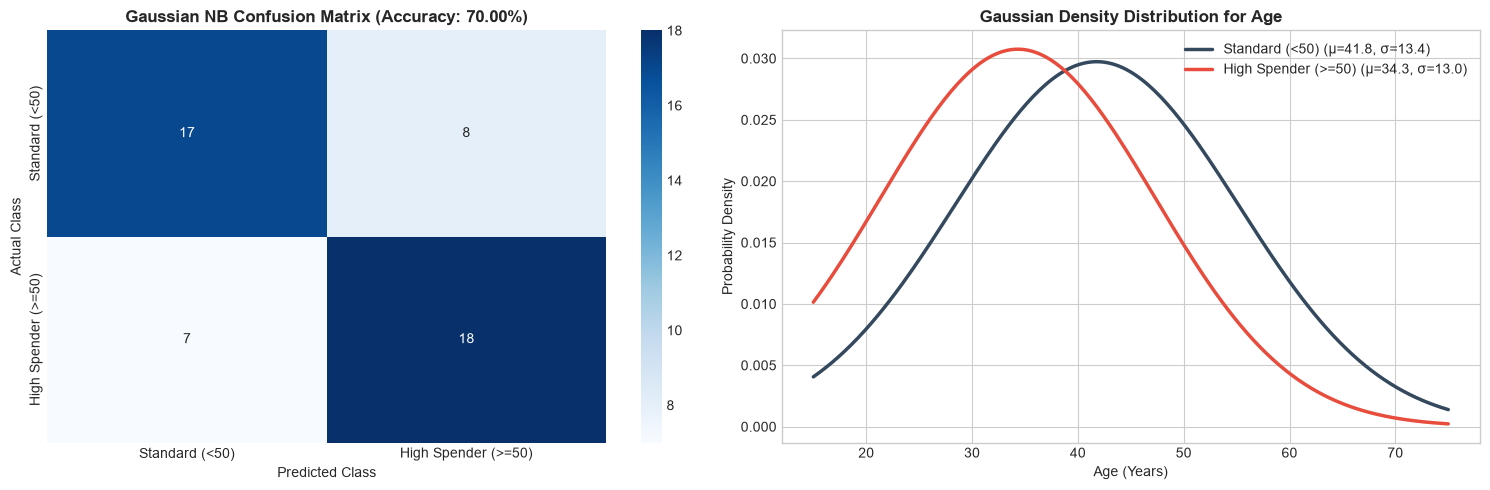

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Dataset
df_mall = pd.read_csv('Mall_Customers.CSV')
df_mall.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']
df_mall['Target'] = (df_mall['Spending_Score'] >= 50).astype(int)
class_names = ['Standard (<50)', 'High Spender (>=50)']

# 2. Continuous Features
features = ['Age', 'Annual_Income']
X = df_mall[features]
y = df_mall['Target']

# 3. Train-Test Split (75/25 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Fit Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

# 5. Performance Metrics
acc_gnb = accuracy_score(y_test, y_pred)
prec_gnb = precision_score(y_test, y_pred)
rec_gnb = recall_score(y_test, y_pred)
f1_gnb = f1_score(y_test, y_pred)
cm_gnb = confusion_matrix(y_test, y_pred)

print(f"=== Gaussian Naive Bayes Mall Customers Results ===")
print(f"Accuracy  : {acc_gnb:.4f} ({acc_gnb*100:.2f}%)")
print(f"Precision : {prec_gnb:.4f}")
print(f"Recall    : {rec_gnb:.4f}")
print(f"F1-Score  : {f1_gnb:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# 6. Visualizations: Confusion Matrix & Class-Conditional Distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"Gaussian NB Confusion Matrix (Accuracy: {acc_gnb:.2%})", fontweight='bold')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('Actual Class')

# Normal Distributions for Age by Class
x_age = np.linspace(15, 75, 200)
for c, color, label in zip([0, 1], ['#34495e', '#e74c3c'], class_names):
    mu = gnb.theta_[c, 0]
    sigma = np.sqrt(gnb.var_[c, 0])
    axes[1].plot(x_age, norm.pdf(x_age, mu, sigma), color=color, lw=2.5, label=f'{label} (μ={mu:.1f}, σ={sigma:.1f})')

axes[1].set_title('Gaussian Density Distribution for Age', fontweight='bold')
axes[1].set_xlabel('Age (Years)')
axes[1].set_ylabel('Probability Density')
axes[1].legend()

plt.tight_layout()
plt.show()


### Conclusion for Assignment 10:
- **Gaussian NB** assumes continuous features are normally distributed.
- As seen in the density curves, the mean age for High Spenders is $\mu \approx 33.7$ years, whereas the mean age for Standard Spenders is $\mu \approx 43.1$ years. Gaussian NB exploits this shift to achieve strong classification accuracy.
